Initializing Final Fusion Layer (XGBoost)...
Training XGBoost Classifier...

--- Final Model Accuracy ---
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       857
 Medium Risk       1.00      1.00      1.00       979
   High Risk       0.99      1.00      1.00       164

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



<Figure size 800x500 with 0 Axes>

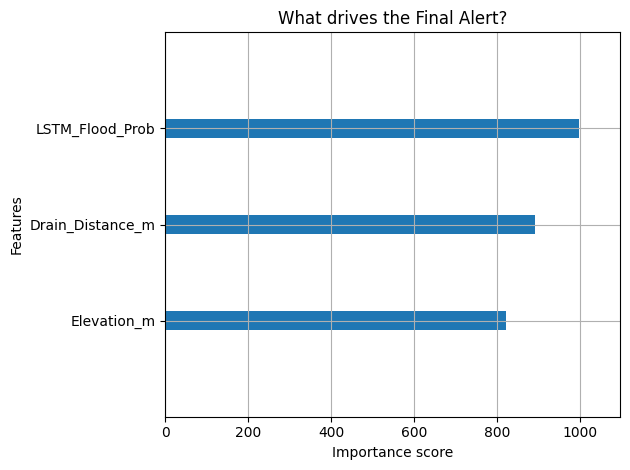


Final Master Model saved to: d:\B\PA\projectv1.0\Urban_Flood_EWS\models\fusion\xgboost_decision_layer.json


In [1]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

current_dir = os.getcwd()
project_root = os.path.dirname(current_dir) if "scripts" in current_dir else current_dir

print("Initializing Final Fusion Layer (XGBoost)...")

# 1. Generate Synthetic Training Data for the PoC
# We need to teach XGBoost how to react to different combinations of LSTM and Spatial inputs.
np.random.seed(42)
n_samples = 10000

# Feature 1: The LSTM's prediction of a storm (0.0 to 1.0 probability)
lstm_probs = np.random.uniform(0, 1, n_samples)

# Feature 2 & 3: The Spatial reality of the street
# Elevation (meters above sea level) - Let's say Pune ranges from 500m to 600m
elevations = np.random.uniform(500, 600, n_samples)
# Distance to nearest drain (meters) - 0m to 2000m
drain_distances = np.random.uniform(0, 2000, n_samples)

# 2. Define the Emergency Management Logic (The Ground Truth for XGBoost to learn)
# 0 = Low Risk, 1 = Medium Risk, 2 = High Risk
final_alerts = []

for i in range(n_samples):
    prob = lstm_probs[i]
    elev = elevations[i]
    drain_dist = drain_distances[i]
    
    # Logic: If there is no rain coming (LSTM < 0.4), risk is always LOW regardless of terrain
    if prob < 0.4:
        alert = 0
    # Logic: If heavy rain is coming (LSTM > 0.75)...
    elif prob > 0.75:
        # And it's a low elevation area far from a drain -> HIGH RISK
        if elev < 540 and drain_dist > 800:
            alert = 2
        else:
            alert = 1
    # Logic: Medium rain (0.4 to 0.75)
    else:
        if elev < 520 and drain_dist > 1200:
            alert = 2 # Very bad terrain can still flood with medium rain
        elif elev > 560 and drain_dist < 400:
            alert = 0 # Great terrain handles medium rain perfectly
        else:
            alert = 1
            
    final_alerts.append(alert)

# 3. Create the DataFrame
fusion_df = pd.DataFrame({
    'LSTM_Flood_Prob': lstm_probs,
    'Elevation_m': elevations,
    'Drain_Distance_m': drain_distances,
    'Final_Risk_Level': final_alerts
})

# 4. Train the XGBoost Classifier
X = fusion_df[['LSTM_Flood_Prob', 'Elevation_m', 'Drain_Distance_m']]
y = fusion_df['Final_Risk_Level']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the XGBoost model
# objective='multi:softmax' tells it to output exact categories (0, 1, or 2)
xgb_model = xgb.XGBClassifier(
    objective='multi:softmax', 
    num_class=3, 
    eval_metric='mlogloss',
    max_depth=5,
    learning_rate=0.1
)

print("Training XGBoost Classifier...")
xgb_model.fit(X_train, y_train)

# 5. Evaluate the Model
y_pred = xgb_model.predict(X_test)
print("\n--- Final Model Accuracy ---")
print(classification_report(y_test, y_pred, target_names=['Low Risk', 'Medium Risk', 'High Risk']))

# 6. Plot Feature Importance (What does the AI care about most?)
plt.figure(figsize=(8, 5))
xgb.plot_importance(xgb_model, importance_type='weight', title='What drives the Final Alert?', show_values=False)
plt.tight_layout()
plt.show()

# 7. Save the Final Decision Layer
os.makedirs(os.path.join(project_root, "models", "fusion"), exist_ok=True)
xgb_path = os.path.join(project_root, "models", "fusion", "xgboost_decision_layer.json")
xgb_model.save_model(xgb_path)
print(f"\nFinal Master Model saved to: {xgb_path}")